# Bank Customer Segmentation: K-Means, PCA, and a Leakage-Free Segment Classifier

**Goal.** Group bank transactions into customer segments that a retention / product team could act on, and test whether a segment can be predicted from information that was *not* used to build it.

**Dataset.** 2,537 raw rows of bank transaction records (account, device, channel, occupation, age, balance, login attempts, ...). The file appears to be synthetic (course-provided), with deliberately injected missing values and duplicates.

**What is different from a standard course submission.** My first version of this project scored a silhouette of ~0.50 and 100% classification accuracy. Both numbers turned out to be artifacts of the pipeline, not of the data. Section 2 reproduces that pipeline and shows why; Sections 3-6 rebuild it properly.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

DATA = 'bank_transactions_data_edited.csv'
SEED = 42
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'   # validated categorical slots 1-3
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e6e5e1'
plt.rcParams.update({'figure.facecolor':'#fcfcfb','axes.facecolor':'#fcfcfb','axes.edgecolor':GRID,
    'axes.labelcolor':MUTED,'xtick.color':MUTED,'ytick.color':MUTED,'text.color':INK,
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.color':GRID,'grid.linewidth':.8,
    'font.size':11,'axes.titlesize':13,'axes.titleweight':'bold','axes.titlelocation':'left'})
raw = pd.read_csv(DATA)
print('Raw shape:', raw.shape)

Raw shape: (2537, 16)


## 1. Data audit

In [2]:
audit = pd.DataFrame({'missing': raw.isnull().sum(), 'missing_%': (raw.isnull().mean()*100).round(1)})
print(audit.T.to_string())
print('\nExact duplicate rows:', raw.duplicated().sum())
print('\nLoginAttempts distribution (raw):')
print(raw['LoginAttempts'].value_counts(dropna=False).sort_index().to_string())

           TransactionID  AccountID  TransactionAmount  PreviousTransactionDate  TransactionType  Location  DeviceID  IP Address  MerchantID  Channel  CustomerAge  CustomerOccupation  TransactionDuration  LoginAttempts  AccountBalance  TransactionDate
missing             29.0       21.0               26.0                     28.0             30.0      30.0      30.0        20.0        23.0     27.0         18.0                23.0                 26.0           21.0            27.0             24.0
missing_%            1.1        0.8                1.0                      1.1              1.2       1.2       1.2         0.8         0.9      1.1          0.7                 0.9                  1.0            0.8             1.1              0.9

Exact duplicate rows: 21

LoginAttempts distribution (raw):
LoginAttempts
1.0    2396
2.0      27
3.0      31
4.0      31
5.0      31
NaN      21


Each column is missing roughly 1% of values and 21 rows are exact duplicates. Note `LoginAttempts`: **95% of rows have exactly 1 attempt**, and the ~5% with 2-5 attempts are the only rows that look like possible anomalies. Keep that in mind for Section 2.

In [3]:
need = ['TransactionAmount','CustomerAge','TransactionDuration','AccountBalance','LoginAttempts',
        'Channel','TransactionType','CustomerOccupation']
df = raw.drop_duplicates().dropna(subset=need).copy()
print(f'Rows kept: {len(df)} of {len(raw)} ({len(raw)-len(df)} removed: duplicates + missing values)')

Rows kept: 2321 of 2537 (216 removed: duplicates + missing values)


## 2. Why my first pipeline gave misleading results

The original version pipeline did four things: label-encode every categorical column, drop rows outside 1.5xIQR on every numeric column, scale only the numeric columns, and run K-Means. Reproducing it:

In [4]:
cols9 = ['TransactionAmount','TransactionType','Location','Channel','CustomerAge','CustomerOccupation',
         'TransactionDuration','LoginAttempts','AccountBalance']
old = raw[cols9].dropna().drop_duplicates().copy()
before_multi = (old['LoginAttempts'] > 1).sum()

num_old = ['TransactionAmount','CustomerAge','TransactionDuration','LoginAttempts','AccountBalance']
for c in num_old:                                     # sequential IQR drop
    q1, q3 = old[c].quantile(.25), old[c].quantile(.75); iqr = q3 - q1
    old = old[(old[c] >= q1 - 1.5*iqr) & (old[c] <= q3 + 1.5*iqr)]
after_multi = (old['LoginAttempts'] > 1).sum()

for c in ['TransactionType','Location','Channel','CustomerOccupation']:
    old[c] = LabelEncoder().fit_transform(old[c])      # Location -> 0..42 in ALPHABETICAL order
old_loc = old['Location'].copy()
old[num_old] = StandardScaler().fit_transform(old[num_old])   # encoded columns stay unscaled

km_old = KMeans(n_clusters=3, random_state=SEED).fit(old)
print(f'Rows with LoginAttempts > 1 before IQR filter: {before_multi}  ->  after: {after_multi}')
print(f'LoginAttempts unique values left: {old["LoginAttempts"].nunique()} (zero variance)')
print(f'Silhouette of old pipeline: {silhouette_score(old, km_old.labels_):.3f}')
tmp = pd.DataFrame({'cluster': km_old.labels_, 'Location_code': old_loc.values})
print('\nLocation code range per cluster:')
print(tmp.groupby('cluster')['Location_code'].agg(['min','max','mean']).round(1).to_string())

Rows with LoginAttempts > 1 before IQR filter: 109  ->  after: 0
LoginAttempts unique values left: 1 (zero variance)


Silhouette of old pipeline: 0.501

Location code range per cluster:
         min  max  mean
cluster                
0         27   42  34.5
1          0   12   6.0
2         13   26  19.4


**Diagnosis**

1. **Every row with more than one login attempt was deleted** by the IQR filter, because with 95% ones, the IQR is zero and anything else counts as an "outlier". The most interesting rows were thrown away, and `LoginAttempts` became a constant column.
2. **The clusters are just three slices of the `Location` code.** `LabelEncoder` numbers the cities alphabetically (0-42), and since encoded columns were not scaled, `Location` has a variance over 100 times larger than any scaled feature (standard deviation ~12 vs. 1) and dominates the distance. The cluster boundaries are non-overlapping ranges of that code.
3. **The silhouette is high because the split is one-dimensional**, not because customers form natural groups.
4. **The classifier then scored 100% because it was trained to predict the K-Means label from the same features K-Means used.** That is circular; it measures how well a tree can re-learn a distance rule.

## 3. Feature engineering (proper)

In [5]:
df['LogAmount']   = np.log1p(df['TransactionAmount'])                 # amounts are right-skewed
df['AmtBalRatio'] = df['TransactionAmount'] / df['AccountBalance']    # how big the transaction is vs. the account
seg_features = ['CustomerAge','AccountBalance','LogAmount','AmtBalRatio','TransactionDuration']
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(df[seg_features]), columns=seg_features, index=df.index)
print('Segmentation features:', seg_features)
print('Rows:', len(X), '| LoginAttempts > 1 rows kept:', int((df['LoginAttempts']>1).sum()))

Segmentation features:

 ['CustomerAge', 'AccountBalance', 'LogAmount', 'AmtBalRatio', 'TransactionDuration']
Rows: 2321 | LoginAttempts > 1 rows kept: 109


Choices: no alphabetical city code; outliers are kept (transaction value is naturally skewed, so I log-transform instead of deleting); `LoginAttempts` is kept in the dataset but held out of the clustering so it can be used later as an independent check; categorical profile columns (occupation, channel, type) are also held out so the classifier in Section 6 is not circular.

## 4. Choosing k

   silhouette   inertia
2       0.251  9029.443
3       0.228  7695.888
4       0.219  6630.162
5       0.226  5766.719
6       0.238  5038.633
7       0.239  4577.330
8       0.227  4220.291


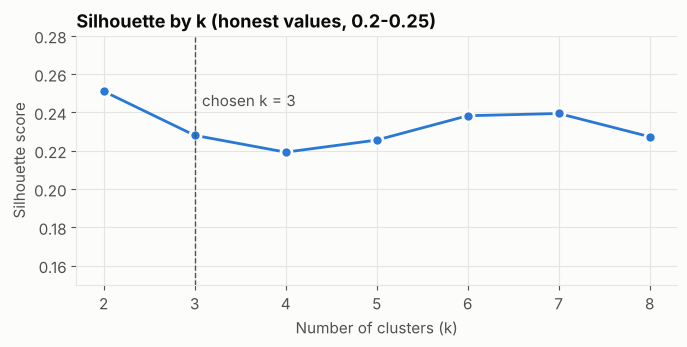

In [6]:
ks = range(2, 9)
sil = {k: silhouette_score(X, KMeans(k, random_state=SEED, n_init=10).fit(X).labels_) for k in ks}
inertia = {k: KMeans(k, random_state=SEED, n_init=10).fit(X).inertia_ for k in ks}
print(pd.DataFrame({'silhouette': sil, 'inertia': inertia}).round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(list(sil), list(sil.values()), color=BLUE, lw=2, marker='o', ms=8, mfc=BLUE, mec='#fcfcfb', mew=2)
ax.axvline(3, color=MUTED, lw=1, ls='--'); ax.text(3.08, max(sil.values()), 'chosen k = 3', color=MUTED, va='top')
ax.set_xlabel('Number of clusters (k)'); ax.set_ylabel('Silhouette score')
ax.set_title('Silhouette by k (honest values, 0.2-0.25)'); ax.set_ylim(0.15, 0.28)
plt.tight_layout(); plt.savefig('figures/silhouette_by_k.png', dpi=160); plt.show()

Silhouette is modest (~0.23-0.25) for every k with no sharp peak: **customers form overlapping groups along a continuum, not isolated islands.** That is a legitimate finding for this dataset, and it is the number I report, not the inflated 0.50. I chose **k = 3** over k = 2 (0.25) because three segments give clearly different business profiles, as shown next, at a negligible cost in silhouette.

## 5. Final segments

In [7]:
km = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit(X)
df['raw_cluster'] = km.labels_
order = df.groupby('raw_cluster')['AccountBalance'].mean().sort_values().index        # rank by balance
names = {order[0]: 'A. Young, low balance', order[1]: 'B. Young, mid balance', order[2]: 'C. Established, high balance'}
df['Segment'] = df['raw_cluster'].map(names)
ages = df.groupby('Segment')['CustomerAge'].mean()
assert ages.idxmax() == 'C. Established, high balance'         # sanity check on the naming

profile = df.groupby('Segment').agg(
    customers=('Segment','size'),
    avg_age=('CustomerAge','mean'),
    avg_balance=('AccountBalance','mean'),
    avg_amount=('TransactionAmount','mean'),
    amt_to_balance=('AmtBalRatio','median'),
    avg_duration_s=('TransactionDuration','mean'),
).round(2)
profile['share_%'] = (profile['customers']/len(df)*100).round(1)
print('Final silhouette (k=3): %.3f' % silhouette_score(X, km.labels_))
print(); print(profile.to_string())
print('\nOccupation mix per segment (row %):')
print((pd.crosstab(df['Segment'], df['CustomerOccupation'], normalize='index')*100).round(0).astype(int).to_string())

Final silhouette (k=3): 0.228

                              customers  avg_age  avg_balance  avg_amount  amt_to_balance  avg_duration_s  share_%
Segment                                                                                                           
A. Young, low balance               106    28.72       445.11      731.12            1.64          127.96      4.6
B. Young, mid balance               845    28.59      2285.07      259.73            0.12          114.25     36.4
C. Established, high balance       1370    55.62      7160.16      288.91            0.03          122.40     59.0

Occupation mix per segment (row %):
CustomerOccupation            Doctor  Engineer  Retired  Student
Segment                                                         
A. Young, low balance             11         8        1       79
B. Young, mid balance              8        27        2       62
C. Established, high balance      37        24       38        0


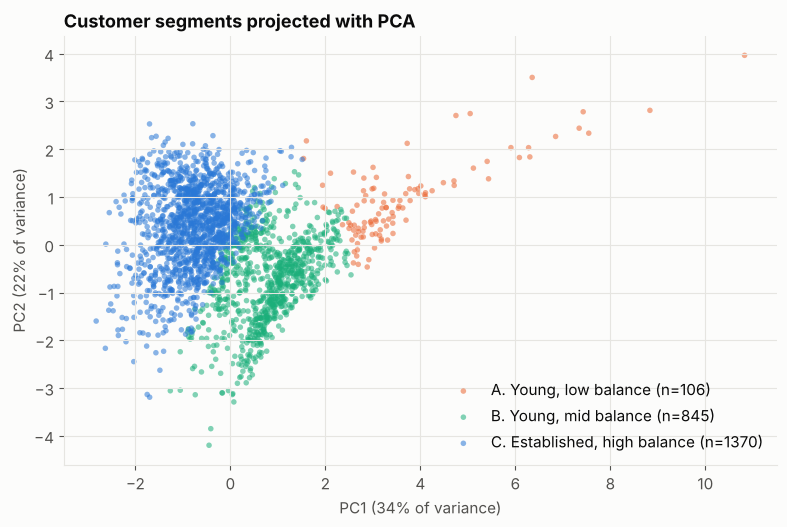

Variance explained by 2 components: 56%


In [8]:
pca = PCA(n_components=2, random_state=SEED).fit(X)
P = pca.transform(X)
colors = {'A. Young, low balance': ORANGE, 'B. Young, mid balance': AQUA, 'C. Established, high balance': BLUE}
fig, ax = plt.subplots(figsize=(8, 5.4))
for name, col in colors.items():
    m = (df['Segment'] == name).values
    ax.scatter(P[m,0], P[m,1], s=16, alpha=.55, color=col, edgecolor='none', label=f'{name} (n={m.sum()})')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% of variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% of variance)')
ax.set_title('Customer segments projected with PCA'); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('figures/segments_pca.png', dpi=160); plt.show()
print('Variance explained by 2 components: %.0f%%' % (pca.explained_variance_ratio_.sum()*100))

**Reading the segments**

- **A. Young, low balance** (~29 years old, average balance ~$445, 79% students; only ~5% of customers): transactions are large relative to the account (median transaction = 1.6x the balance, versus 0.03-0.12x in the other segments). A small, high-attention group: candidates are liquidity / overdraft-risk monitoring and small-ticket savings products.
- **B. Young, mid balance** (~29 years old, average balance ~$2,300, 36% of customers): the growth segment. Candidates: auto-save rules and first investment or credit products.
- **C. Established, high balance** (mid-50s, average balance ~$7,200, 59% of customers; doctors, engineers and retirees): the retention and wealth segment. Candidates: relationship management, deposits and low-risk investment products.

The segments are driven mainly by life stage (age), wealth (balance) and how large transactions are relative to the balance. They overlap (see the PCA plot, silhouette ~0.23), so they are better used as soft targeting groups than as hard rules.

## 6. Can a segment be predicted from information the clustering never saw?

In [9]:
clf_features = ['CustomerOccupation','Channel','TransactionType','LoginAttempts']   # NOT used to build the clusters
Xc = pd.get_dummies(df[clf_features], dtype=float)
y = df['Segment']
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
models = {'Majority-class baseline': DummyClassifier(strategy='most_frequent'),
          'Decision Tree (depth 3)': DecisionTreeClassifier(max_depth=3, random_state=SEED),
          'Random Forest':           RandomForestClassifier(300, min_samples_leaf=10, random_state=SEED)}
rows = []
for n, m in models.items():
    r = cross_validate(m, Xc, y, cv=cv, scoring=['accuracy','f1_macro'])
    rows.append({'model': n, 'accuracy': r['test_accuracy'].mean(), 'macro_F1': r['test_f1_macro'].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

pred = cross_val_predict(models['Random Forest'], Xc, y, cv=cv)
labels = sorted(y.unique())
print('\nConfusion matrix (rows = actual, cols = predicted), cross-validated Random Forest:')
print(pd.DataFrame(confusion_matrix(y, pred, labels=labels), index=labels, columns=[l[:1] for l in labels]).to_string())
rf = models['Random Forest'].fit(Xc, y)
print('\nTop features:'); print(pd.Series(rf.feature_importances_, index=Xc.columns).sort_values(ascending=False).head(5).round(3).to_string())

                  model  accuracy  macro_F1
Majority-class baseline     0.590     0.247
Decision Tree (depth 3)     0.816     0.537
          Random Forest     0.815     0.536



Confusion matrix (rows = actual, cols = predicted), cross-validated Random Forest:
                              A    B     C
A. Young, low balance         0   84    22
B. Young, mid balance         0  527   318
C. Established, high balance  0    5  1365



Top features:
CustomerOccupation_Student     0.584
CustomerOccupation_Retired     0.202
CustomerOccupation_Doctor      0.127
CustomerOccupation_Engineer    0.071
Channel_Branch                 0.003


Evaluated with 5-fold cross-validation on **features that were not used to form the segments**, accuracy is 0.82 versus a 0.59 majority-class baseline (macro-F1 0.54 versus 0.25). The gain comes almost entirely from occupation: it identifies the older, high-balance segment C almost perfectly (recall ~99.6%) and partly separates B, but **segment A is never predicted** (recall 0%) and 38% of B is mistaken for C. Occupation and channel tell you roughly *which life stage* a customer is in, but not their balance tier or spending pattern. Those have to be observed directly, which is why the segments should be recomputed from transaction data rather than guessed from a profile.

## 7. Negative result: can login anomalies be predicted?

In [10]:
Xa = pd.get_dummies(df[['LogAmount','CustomerAge','TransactionDuration','AccountBalance','AmtBalRatio',
                        'Channel','TransactionType','CustomerOccupation']], dtype=float)
ya = (df['LoginAttempts'] > 1).astype(int)
auc = cross_val_score(RandomForestClassifier(300, min_samples_leaf=5, class_weight='balanced', random_state=SEED),
                      Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='roc_auc')
print(f'Share of transactions with >1 login attempt: {ya.mean()*100:.1f}%')
print(f'Cross-validated ROC-AUC for predicting them: {auc.mean():.3f} (+/- {auc.std():.3f}); 0.5 = random guessing')
print('\nShare of multi-login transactions per segment (%):')
print((df.groupby('Segment')['LoginAttempts'].apply(lambda s: (s>1).mean()*100)).round(1).to_string())

Share of transactions with >1 login attempt: 4.7%
Cross-validated ROC-AUC for predicting them: 0.516 (+/- 0.027); 0.5 = random guessing

Share of multi-login transactions per segment (%):
Segment
A. Young, low balance           2.8
B. Young, mid balance           4.5
C. Established, high balance    5.0


ROC-AUC is ~0.5: **none of the available attributes predicts multiple login attempts**, and the rate is similar across segments (3-5%; segment A is too small to read precisely). This is consistent with a synthetic dataset where that field was generated independently. I am reporting it rather than forcing a fraud model on noise; a real fraud project would need labelled fraud outcomes and device/IP/time-based features.

## 8. Summary

| Item | Naive pipeline | Rebuilt pipeline |
|---|---|---|
| Rows with multi-login attempts | all removed | kept |
| Cluster driver | alphabetical city code | age and balance (profiled) |
| Silhouette | ~0.50 (inflated) | ~0.23 (honest) |
| Classifier | 100% accuracy, circular | cross-validated, on held-out features, vs. baseline |
| Takeaway | none | 3 actionable life-stage / wealth segments; login anomalies not predictable |

**Limitations.** Synthetic data; moderate cluster separation; segments reflect age and balance more than behavior. **Next steps.** Add real behavioral features (frequency, recency, merchant category), validate stability with bootstrapped re-clustering, and test alternatives (Gaussian mixtures, hierarchical clustering).